# One full plate: figure gallery

Companion to [ops_full_plate](ops_full_plate.ipynb). The same plate-1 cells, the same normalization and the same two
aggregation routes, followed by the standard mantispy figures for quality control, hit calling, phenotype strength
against viability, embeddings at the cell, guide and gene level, and the gene landscape. Every figure is also written to
`FIGS` as a PNG.

In [1]:
import os
import time
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import scanpy as sc
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

import mantispy as mt

warnings.filterwarnings("ignore")
sc.settings.verbosity = 0
plt.rcParams["figure.dpi"] = 110
SEED = 0
CELLS = os.environ.get("OPS_CELLS", "aconcagua_plate1_cells.h5ad")
FIGS = Path(os.environ.get("OPS_FIGS", "figs"))
FIGS.mkdir(parents=True, exist_ok=True)
NJOBS = len(os.sched_getaffinity(0))
T0 = time.time()
HIT, NULL, NTC_C, UNEXP = "crimson", "lightgrey", "tab:blue", "darkorange"


def lap(what):
    print(f"[{time.time() - T0:6.0f}s] {what}")


def save(name, fig=None):
    fig = fig or plt.gcf()
    fig.savefig(FIGS / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

/home/icb/tim.treis/.local/share/hatch/env/virtual/mantispy/NWI7QaJt/tutorials/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Preparation (as in the main notebook)

In [2]:
cells = ad.read_h5ad(CELLS)
obs = cells.obs
ntc = (obs["Metadata_Control_Type"] == "negcon").to_numpy()
raw_qc = obs[["Metadata_Well", "Metadata_X", "Metadata_Y", "Metadata_Site", "Metadata_Mitotic", "Metadata_ClassConfidence",
              "Metadata_BarcodeDistance", "Metadata_MappedBarcodes", "Metadata_Gene", "Metadata_Guide"]].copy()
DNA = "Nuclei_Intensity_IntegratedIntensity_DAPI"
rng = np.random.default_rng(SEED)
sub_idx = np.sort(rng.choice(cells.n_obs, size=150_000, replace=False))
raw_sub = cells[sub_idx].copy()  # unnormalized single cells for cell-level figures
lap("loaded")

mt.pp.normalize(cells, by=["Metadata_Plate", "Metadata_Well"], reference="negcon")
ntc_guides = np.sort(obs.loc[ntc, "Metadata_Guide"].astype(str).unique())
roll = np.random.default_rng(SEED).permutation(ntc_guides)
role = dict.fromkeys(roll[:100], "ntc_scale") | dict.fromkeys(roll[100:200], "nontargeting")
role |= {g: f"PSEUDO{i // 4:02d}" for i, g in enumerate(roll[200 : 200 + 4 * ((len(roll) - 200) // 4)])}
unit = {g: f"NTC{i // 4:02d}" for i, g in enumerate(roll[: 4 * (len(roll) // 4)])}
guide = obs["Metadata_Guide"].astype(str)
gene = obs["Metadata_Gene"].astype(str)
obs["Analysis_Group"] = pd.Categorical(np.where(guide.map(role).notna(), guide.map(role), gene))
obs["Gene_Unit"] = pd.Categorical(np.where(guide.map(unit).notna(), guide.map(unit), np.where(ntc, "dropped", gene)))

guide_well = mt.tl.aggregate(cells, by=("Metadata_Plate", "Metadata_Well", "Metadata_Guide"), func="median", min_cells=5)
keep = (obs["Gene_Unit"].astype(str) != "dropped").to_numpy()
gene_well = mt.tl.aggregate(cells[keep], by=("Metadata_Plate", "Metadata_Well", "Gene_Unit"), func="median", min_cells=5)
norm_sub = cells[sub_idx].copy()
mito_gene = obs[keep].groupby("Gene_Unit", observed=True)["Metadata_Mitotic"].mean()
cells_per_guide = obs.groupby("Metadata_Guide", observed=True).size()
cells_per_unit = obs[keep].groupby("Gene_Unit", observed=True).size()
degenerate = cells.var["degenerate_scale"].to_numpy()
del cells
lap("aggregated")

guide_well.X = np.nan_to_num(guide_well.X)
gene_well.X = np.nan_to_num(gene_well.X)
mt.pp.feature_select(guide_well)
chosen = guide_well.var["selected"].to_numpy() & ~degenerate
guide_well_all = guide_well
guide_well = guide_well[:, chosen].copy()
gene_well = gene_well[:, chosen].copy()
guides = mt.tl.aggregate(guide_well, by=("Metadata_Guide",), func="median", min_cells=1)
genes = mt.tl.aggregate(gene_well, by=("Gene_Unit",), func="median", min_cells=1)
for a in (guide_well, gene_well, guides, genes):
    a.X = np.nan_to_num(a.X)
gene_well.obs["Gene_Unit"] = gene_well.obs["Gene_Unit"].astype(str)
lap("features")

[    41s] loaded


[   213s] aggregated


[   226s] features


In [3]:
unexpressed = mt.io.unexpressed_genes(mt.ds.depmap_expression(), "ACH-001086")
sc.pp.pca(guides, n_comps=50, random_state=SEED)
mt.tl.guide_activity(guides, reference="ntc_scale", group="Analysis_Group", use_rep="X_pca")
mt.tl.aggregate_guides(
    guides, score="guide_activity", guide="Metadata_Guide", gene="Analysis_Group", control="nontargeting", n_null=20000, seed=SEED
)
g_calls = pd.DataFrame(guides.uns["mantispy"]["gene_aggregation"]).set_index("group")
g_calls = g_calls[~g_calls.index.str.startswith(("PSEUDO", "ntc_scale", "nontargeting"))]


def efdr(scores):
    table = ad.AnnData(obs=pd.DataFrame({"gene": scores.index, "score": scores.to_numpy()}, index=scores.index))
    mt.tl.empirical_fdr(
        table, control_genes=sorted(set(scores.index) & unexpressed), score="score", group="gene", alpha=0.05, criterion="q"
    )
    return pd.DataFrame(table.uns["mantispy"]["empirical_fdr"]).set_index("group").reindex(scores.index)


e = efdr(g_calls["statistic"])
g_calls["beyond_cutting"] = e["is_hit"].astype(bool)
g_calls["unexpressed"] = g_calls.index.isin(unexpressed)

sc.pp.pca(gene_well, n_comps=50, random_state=SEED)
mt.tl.map(gene_well, mode="activity", label="Gene_Unit", reference="negcon", use_rep="X_pca", null_size=20000, n_jobs=NJOBS, key_added="activity")
p_calls = gene_well.uns["mantispy"]["activity"].set_index("Gene_Unit")
p_calls = p_calls[~p_calls.index.str.startswith("NTC")].copy()
p_calls["beyond_cutting"] = efdr(p_calls["score"])["is_hit"].astype(bool)
p_calls["unexpressed"] = p_calls.index.isin(unexpressed)
lap("calls")

[   657s] calls


## Quality control

Cells per well, how cells spread across each well, the screen's own quality columns (barcode mapping, classifier
confidence), and how much of the profile variance the well explains.

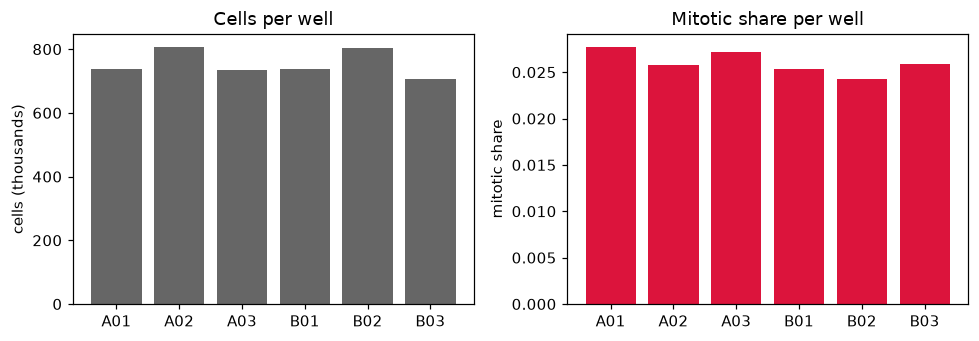

In [4]:
per_well = raw_qc.groupby("Metadata_Well", observed=True).agg(cells=("Metadata_Gene", "size"), mitotic=("Metadata_Mitotic", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].bar(per_well.index.astype(str), per_well["cells"] / 1e3, color="0.4")
axes[0].set(ylabel="cells (thousands)", title="Cells per well")
axes[1].bar(per_well.index.astype(str), per_well["mitotic"], color=HIT)
axes[1].set(ylabel="mitotic share", title="Mitotic share per well")
fig.tight_layout()
save("qc_cells_per_well", fig)

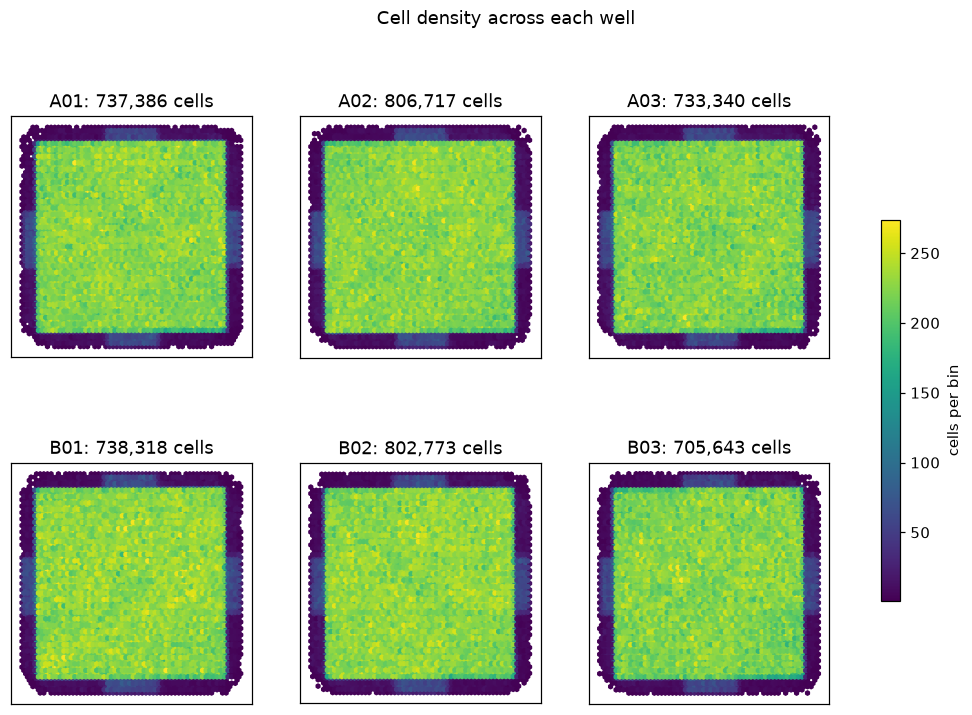

In [5]:
wells = sorted(raw_qc["Metadata_Well"].astype(str).unique())
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for ax, w in zip(axes.ravel(), wells):
    q = raw_qc[raw_qc["Metadata_Well"].astype(str) == w]
    hb = ax.hexbin(q["Metadata_X"], q["Metadata_Y"], gridsize=60, cmap="viridis", mincnt=1)
    ax.set(title=f"{w}: {len(q):,} cells", xticks=[], yticks=[], aspect="equal")
fig.colorbar(hb, ax=axes, shrink=0.6, label="cells per bin")
fig.suptitle("Cell density across each well")
save("qc_well_density", fig)

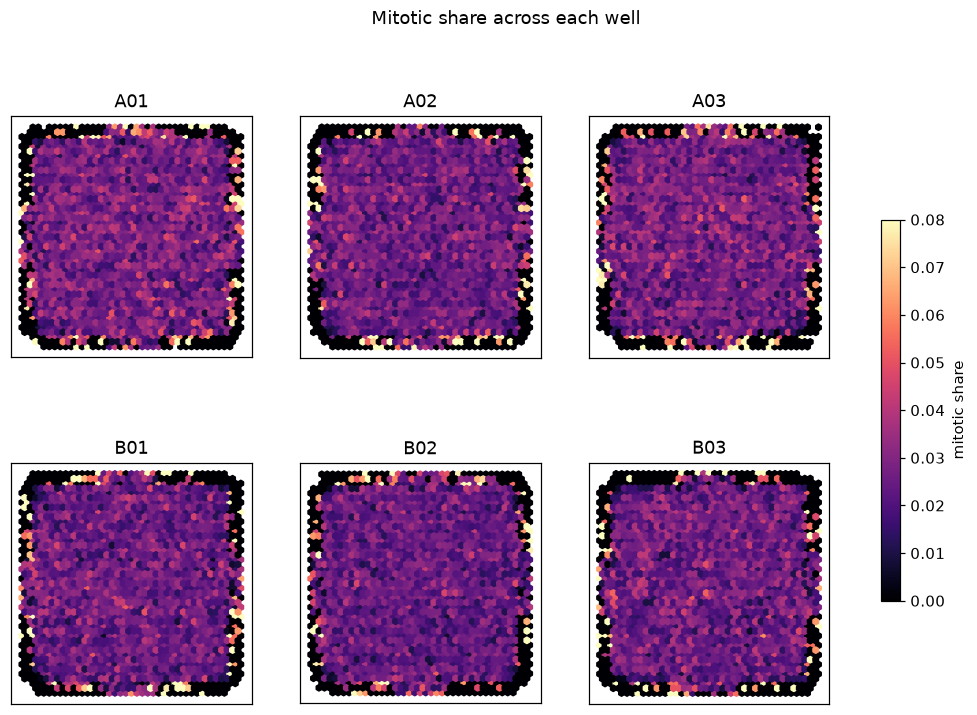

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for ax, w in zip(axes.ravel(), wells):
    q = raw_qc[raw_qc["Metadata_Well"].astype(str) == w]
    hb = ax.hexbin(q["Metadata_X"], q["Metadata_Y"], C=q["Metadata_Mitotic"], reduce_C_function=np.mean, gridsize=40, cmap="magma", vmin=0, vmax=0.08)
    ax.set(title=w, xticks=[], yticks=[], aspect="equal")
fig.colorbar(hb, ax=axes, shrink=0.6, label="mitotic share")
fig.suptitle("Mitotic share across each well")
save("qc_well_mitotic_map", fig)

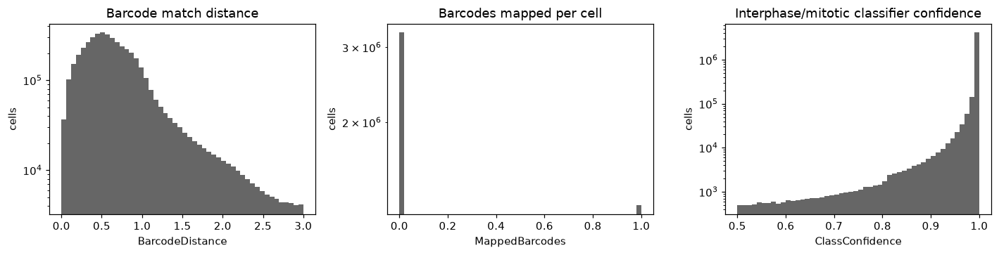

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, title in zip(
    axes,
    ["Metadata_BarcodeDistance", "Metadata_MappedBarcodes", "Metadata_ClassConfidence"],
    ["Barcode match distance", "Barcodes mapped per cell", "Interphase/mitotic classifier confidence"],
):
    v = pd.to_numeric(raw_qc[col], errors="coerce").dropna()
    ax.hist(v, bins=50, color="0.4", log=True)
    ax.set(title=title, xlabel=col.replace("Metadata_", ""), ylabel="cells")
fig.tight_layout()
save("qc_barcode_and_classifier", fig)

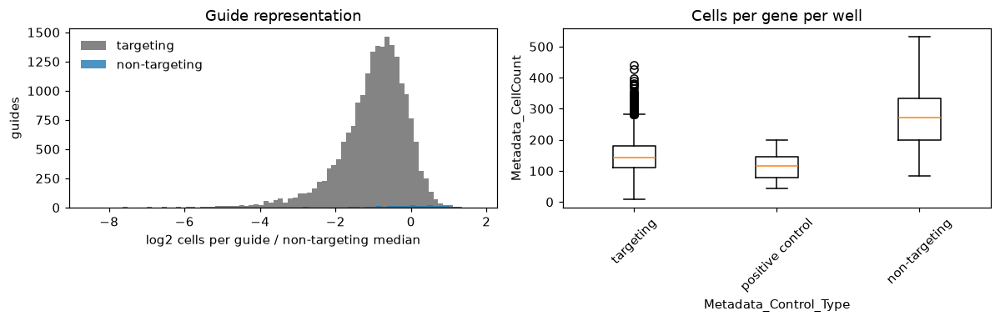

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ratio_guide = cells_per_guide / cells_per_guide[cells_per_guide.index.isin(ntc_guides)].median()
axes[0].hist(np.log2(ratio_guide[~ratio_guide.index.isin(ntc_guides)]), bins=80, color="0.4", alpha=0.8, label="targeting")
axes[0].hist(np.log2(ratio_guide[ratio_guide.index.isin(ntc_guides)]), bins=40, color=NTC_C, alpha=0.8, label="non-targeting")
axes[0].set(xlabel="log2 cells per guide / non-targeting median", ylabel="guides", title="Guide representation")
axes[0].legend(frameon=False)
mt.pl.cell_counts(gene_well, groupby="Metadata_Control_Type", labels={"negcon": "non-targeting", "treatment": "targeting", "poscon": "positive control"}, ax=axes[1])
axes[1].set_title("Cells per gene per well")
fig.tight_layout()
save("qc_representation", fig)

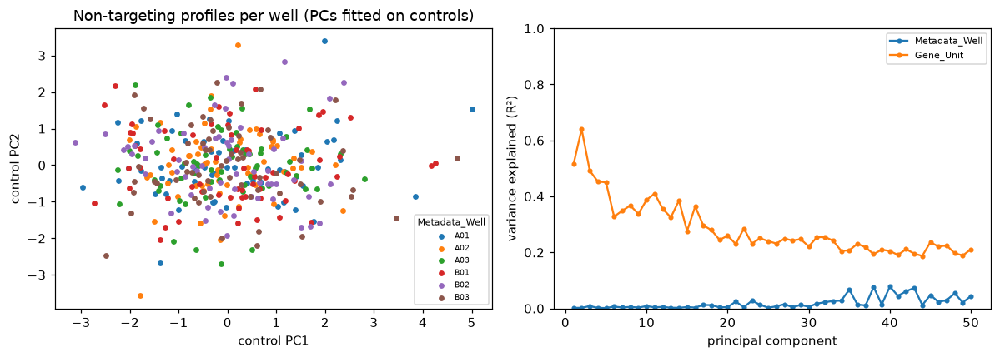

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
mt.pl.control_drift(gene_well, groupby="Metadata_Well", ax=axes[0])
axes[0].set_title("Non-targeting profiles per well (PCs fitted on controls)")
mt.pl.batch_variance(gene_well, keys=["Metadata_Well", "Gene_Unit"], use_rep="X_pca", ax=axes[1])
fig.tight_layout()
save("qc_well_drift_and_variance", fig)

percent replicating (gene x well, 6 wells): 63.5% of 882


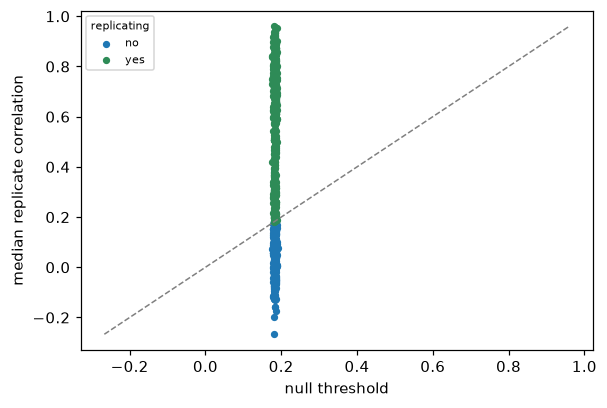

In [10]:
# A dense similarity over every gene x well row does not fit, so score the hits, 500 random genes and the controls.
pick_units = set(p_calls.index[p_calls["beyond_cutting"]]) | set(np.random.default_rng(SEED).choice(p_calls.index, 500, replace=False))
units = gene_well.obs["Gene_Unit"]
rep = gene_well[(units.isin(pick_units) | units.str.startswith("NTC")).to_numpy()].copy()
mt.tl.percent_replicating(rep, groupby="Gene_Unit", metric="pearson", use_rep="X_pca", seed=SEED)
pr = rep.uns["mantispy"]["percent_replicating"]
print(f"percent replicating (gene x well, 6 wells): {pr['is_significant'].mean():.1%} of {len(pr)}")
fig, ax = plt.subplots(figsize=(6, 4))
mt.pl.replicate_correlation(rep, key="percent_replicating", ax=ax)
save("qc_replicate_correlation", fig)

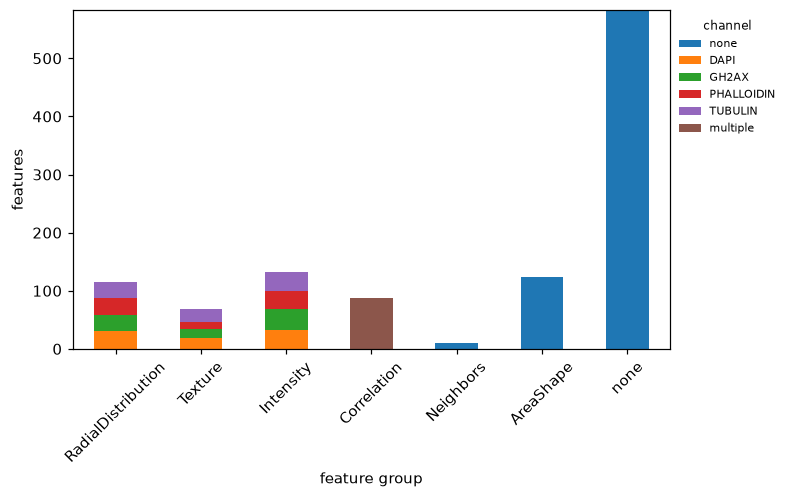

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
mt.pl.feature_groups(guide_well_all, key="selected", ax=ax)
save("qc_feature_groups_selected", fig)

## Hit calling

The guide route (Stouffer over guides) and the pooled route (activity mAP of a gene's wells) as in the main notebook,
plus mantispy's Mahalanobis hit calling ({func}`~mantispy.tl.hit_calling`) on the pooled gene × well profiles.

Mahalanobis hits: 4751 of 5111


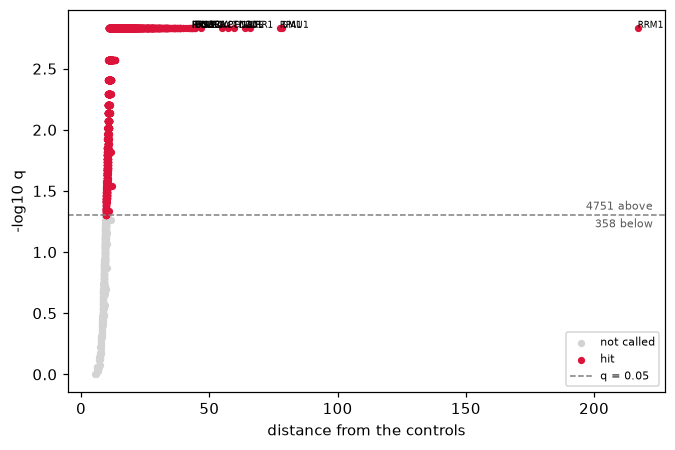

In [12]:
mt.tl.hit_calling(gene_well, groupby="Gene_Unit", use_rep="X_pca", n_permutations=1000)
hits_tab = gene_well.uns["mantispy"]["hits"]
print(f"Mahalanobis hits: {int(hits_tab['is_hit'].sum())} of {len(hits_tab)}")
fig, ax = plt.subplots(figsize=(7, 4.5))
mt.pl.hits(gene_well, label_top=15, ax=ax)
save("hits_mahalanobis", fig)

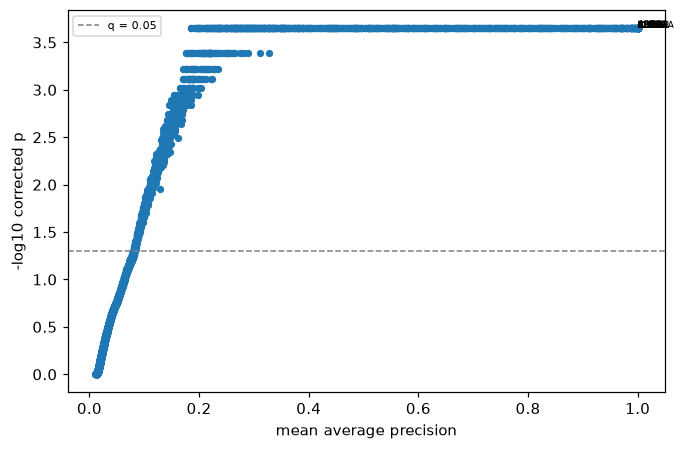

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
mt.pl.map(gene_well, key="activity", label_top=15, ax=ax)
save("hits_map_activity", fig)

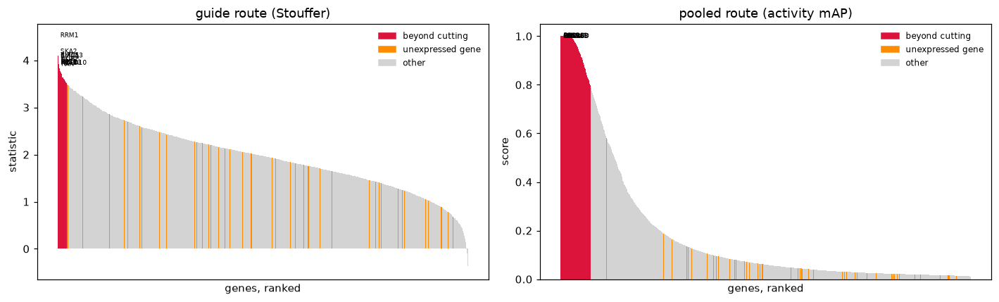

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, calls, col) in zip(axes, [("guide route (Stouffer)", g_calls, "statistic"), ("pooled route (activity mAP)", p_calls, "score")]):
    r = calls.sort_values(col, ascending=False)
    colors = np.where(r["beyond_cutting"], HIT, np.where(r["unexpressed"], UNEXP, NULL))
    ax.bar(np.arange(len(r)), r[col], color=colors, width=1.0)
    for k, g in enumerate(r.index[:12]):
        ax.text(k + 30, r[col].iloc[k], g, fontsize=6, va="center")
    ax.set(xlabel="genes, ranked", ylabel=col, title=name, xticks=[])
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in (HIT, UNEXP, NULL)],
              labels=["beyond cutting", "unexpressed gene", "other"], frameon=False, fontsize=8)
fig.tight_layout()
save("hits_ranked", fig)

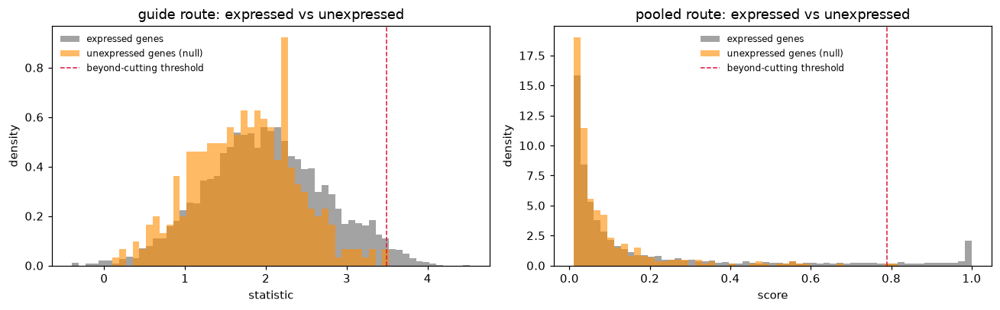

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, calls, col) in zip(axes, [("guide route", g_calls, "statistic"), ("pooled route", p_calls, "score")]):
    bins = np.linspace(calls[col].min(), calls[col].max(), 60)
    ax.hist(calls.loc[~calls["unexpressed"], col], bins=bins, density=True, alpha=0.6, color="0.4", label="expressed genes")
    ax.hist(calls.loc[calls["unexpressed"], col], bins=bins, density=True, alpha=0.6, color=UNEXP, label="unexpressed genes (null)")
    cut = calls.loc[calls["beyond_cutting"], col].min()
    if np.isfinite(cut):
        ax.axvline(cut, color=HIT, ls="--", lw=1, label="beyond-cutting threshold")
    ax.set(xlabel=col, ylabel="density", title=f"{name}: expressed vs unexpressed")
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save("hits_empirical_null", fig)

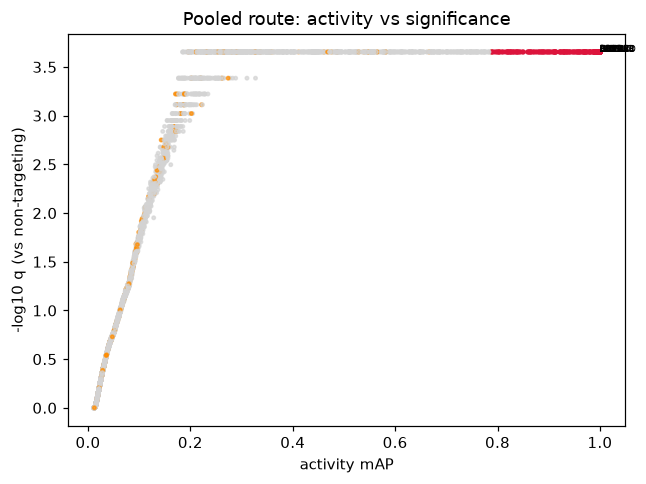

In [16]:
fig, ax = plt.subplots(figsize=(6, 4.5))
q = p_calls["qvalue"].clip(lower=1e-6) if "qvalue" in p_calls else p_calls.filter(like="q").iloc[:, 0].clip(lower=1e-6)
colors = np.where(p_calls["beyond_cutting"], HIT, np.where(p_calls["unexpressed"], UNEXP, NULL))
ax.scatter(p_calls["score"], -np.log10(q), s=5, c=colors, alpha=0.7)
for g in p_calls.sort_values("score", ascending=False).index[:15]:
    ax.annotate(g, (p_calls.loc[g, "score"], -np.log10(q[g])), fontsize=6)
ax.set(xlabel="activity mAP", ylabel="-log10 q (vs non-targeting)", title="Pooled route: activity vs significance")
fig.tight_layout()
save("hits_map_volcano", fig)

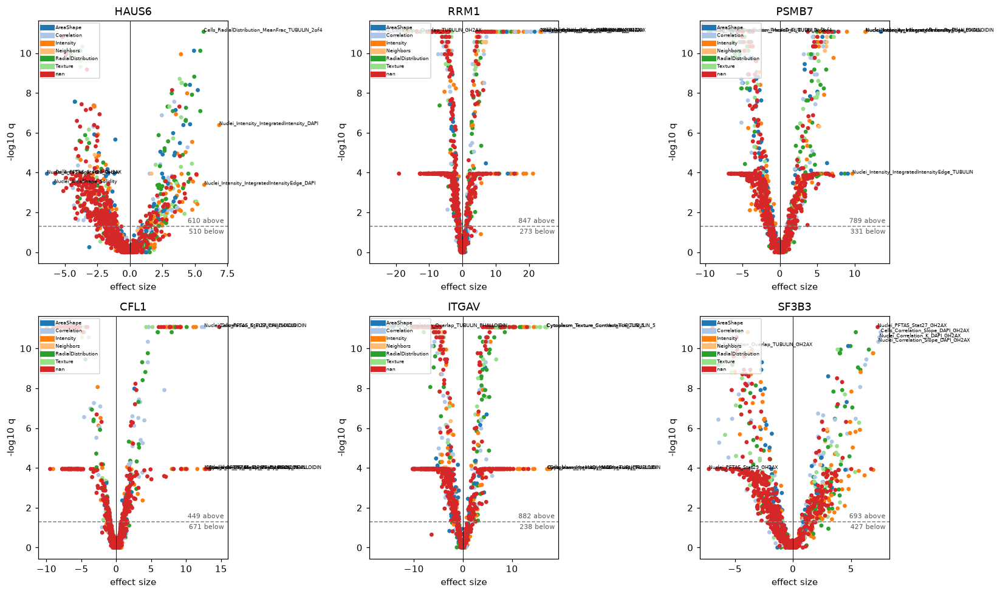

In [17]:
EXAMPLES = ["HAUS6", "RRM1", "PSMB7", "CFL1", "ITGAV", "SF3B3"]
sub = gene_well[(gene_well.obs["Gene_Unit"].isin(EXAMPLES) | (gene_well.obs["Metadata_Control_Type"] == "negcon")).to_numpy()].copy()
sub.obs["Metadata_Gene"] = sub.obs["Metadata_Gene"].astype(str)
mt.tl.effect_size(sub, groupby="Metadata_Gene", reference="negcon")
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, g in zip(axes.ravel(), EXAMPLES):
    try:
        mt.pl.feature_volcano(sub, group=g, label_top=6, ax=ax)
        ax.set_title(g)
    except Exception as err:
        ax.set_title(f"{g}: {err}")
fig.tight_layout()
save("hits_feature_volcanoes", fig)

## Phenotype strength against viability

In a pooled screen the cell count of a gene, relative to the non-targeting guides, is a fitness readout: knockouts of
essential genes leave fewer cells. Plotting phenotype strength against it separates genes that change morphology from
genes that mostly kill the cell.

suspect (lost cells and moved): 840 of 5111


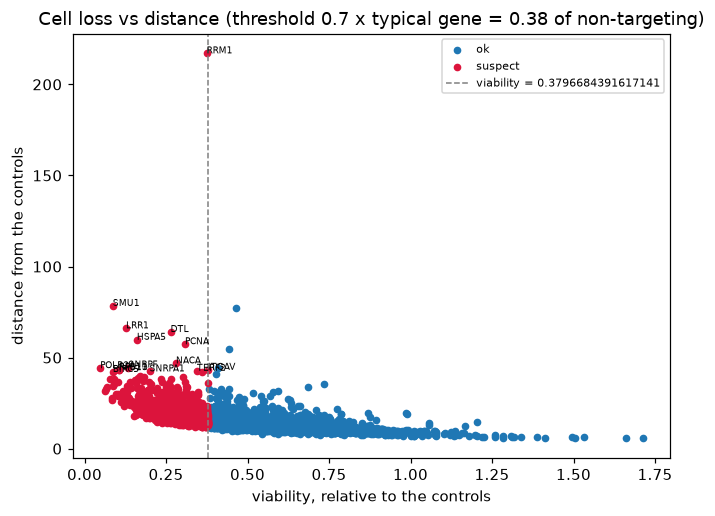

In [18]:
# Every guide spreads over every field of view, so cell counts are compared as they are, not per field.
# Non-targeting guides carry more cells than targeting ones (library representation), so the loss threshold is set
# relative to the typical targeting gene: 0.7 of its count, expressed on the non-targeting scale the tool uses.
typ = cells_per_unit[~cells_per_unit.index.str.startswith("NTC")].median() / cells_per_unit[cells_per_unit.index.str.startswith("NTC")].median()
mt.tl.cytotoxicity(gene_well, groupby="Gene_Unit", site_key=None, min_viability=0.7 * typ)
cyto = gene_well.uns["mantispy"]["cytotoxicity"]
print(f"suspect (lost cells and moved): {int(cyto['suspect'].sum())} of {len(cyto)}")
fig, ax = plt.subplots(figsize=(7, 5))
mt.pl.cytotoxicity(gene_well, label_top=15, ax=ax)
ax.set_title(f"Cell loss vs distance (threshold 0.7 x typical gene = {0.7 * typ:.2f} of non-targeting)")
save("viability_cytotoxicity", fig)

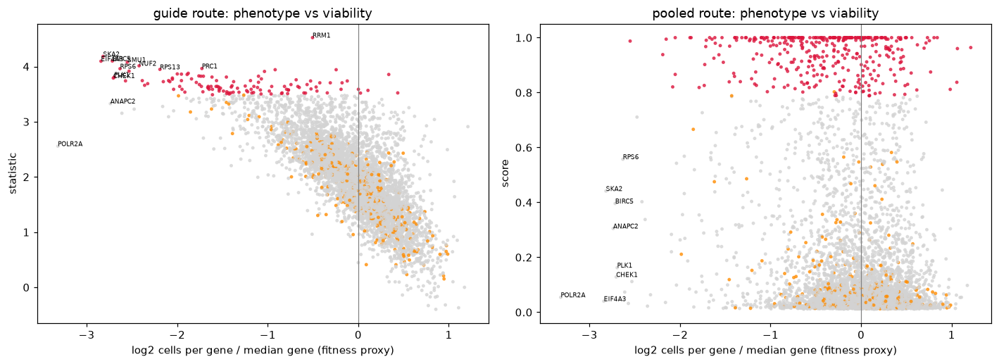

In [19]:
gene_med = cells_per_unit[~cells_per_unit.index.str.startswith("NTC")].median()
viab = np.log2(cells_per_unit / gene_med)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (name, calls, col) in zip(axes, [("guide route", g_calls, "statistic"), ("pooled route", p_calls, "score")]):
    v = viab.reindex(calls.index)
    colors = np.where(calls["beyond_cutting"], HIT, np.where(calls["unexpressed"], UNEXP, NULL))
    order = np.argsort(calls["beyond_cutting"].to_numpy())
    ax.scatter(v.iloc[order], calls[col].iloc[order], s=5, c=colors[order], alpha=0.7)
    ax.axvline(0, color="0.5", lw=0.8)
    strong = calls[col].rank(ascending=False) <= 10
    depleted = v.rank() <= 8
    for g in calls.index[(strong | depleted).to_numpy()]:
        ax.annotate(g, (v[g], calls.loc[g, col]), fontsize=6)
    ax.set(xlabel="log2 cells per gene / median gene (fitness proxy)", ylabel=col, title=f"{name}: phenotype vs viability")
fig.tight_layout()
save("viability_vs_strength", fig)

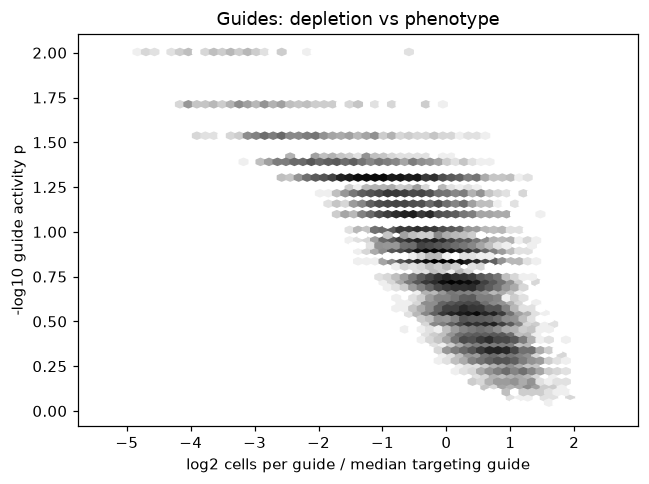

In [20]:
fig, ax = plt.subplots(figsize=(6, 4.5))
gp = guides.obs.set_index("Metadata_Guide")
t = gp[~gp["Analysis_Group"].astype(str).str.match(r"^(PSEUDO|ntc_scale|nontargeting)")]
x = np.log2(cells_per_guide.reindex(t.index) / cells_per_guide[~cells_per_guide.index.isin(ntc_guides)].median())
y = -np.log10(t["guide_activity"].astype(float))
ax.hexbin(x, y, gridsize=60, bins="log", cmap="Greys")
ax.set(xlabel="log2 cells per guide / median targeting guide", ylabel="-log10 guide activity p", title="Guides: depletion vs phenotype")
fig.tight_layout()
save("viability_guides_hexbin", fig)

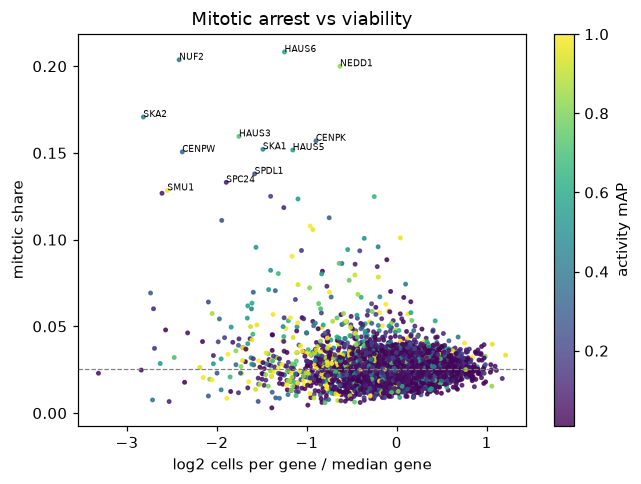

In [21]:
fig, ax = plt.subplots(figsize=(6, 4.5))
m = mito_gene.reindex(p_calls.index)
v = viab.reindex(p_calls.index)
sc_ = ax.scatter(v, m, s=5, c=p_calls["score"], cmap="viridis", alpha=0.8)
for g in m.sort_values(ascending=False).index[:12]:
    ax.annotate(g, (v[g], m[g]), fontsize=6)
ax.axhline(float(mito_gene[mito_gene.index.str.startswith("NTC")].median()), color="0.5", ls="--", lw=0.8)
fig.colorbar(sc_, ax=ax, label="activity mAP")
ax.set(xlabel="log2 cells per gene / median gene", ylabel="mitotic share", title="Mitotic arrest vs viability")
fig.tight_layout()
save("viability_vs_mitotic", fig)

## Single cells

A random 150,000 of the plate's cells: their embedding, the cell cycle read from DNA content, and which cell
subpopulations each knockout over-fills.

[   940s] single-cell embedding


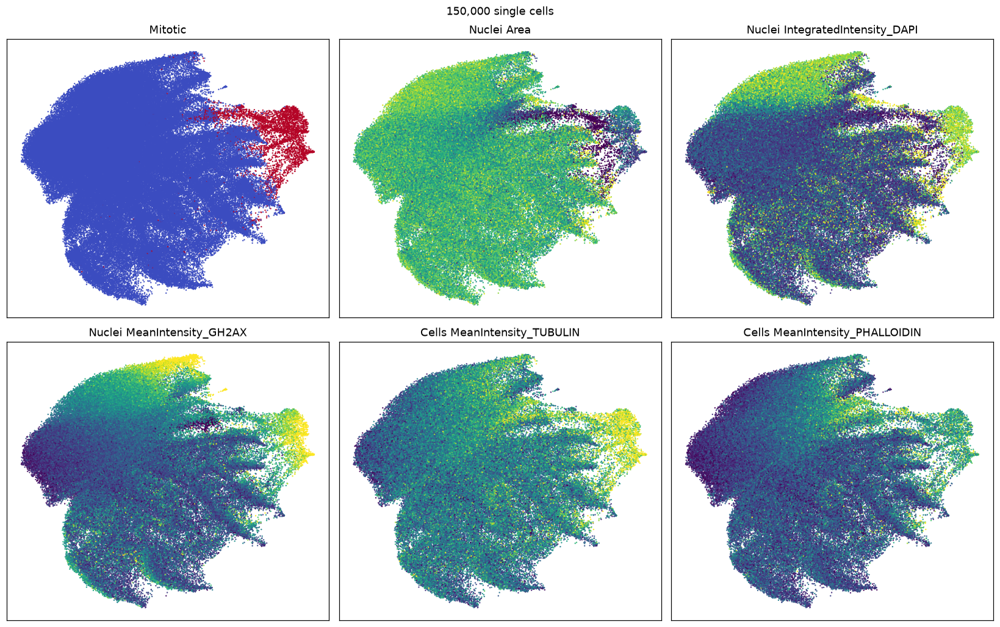

In [22]:
norm_sub = norm_sub[:, chosen].copy()
norm_sub.X = np.nan_to_num(np.clip(norm_sub.X, -50, 50))
sc.pp.pca(norm_sub, n_comps=50, random_state=SEED)
sc.pp.neighbors(norm_sub, n_neighbors=15, random_state=SEED)
sc.tl.umap(norm_sub, random_state=SEED)
sc.tl.leiden(norm_sub, resolution=0.5, key_added="leiden", flavor="igraph", n_iterations=2, random_state=SEED)
lap("single-cell embedding")
u = norm_sub.obsm["X_umap"]
feats = [f for f in ["Nuclei_AreaShape_Area", DNA, "Nuclei_Intensity_MeanIntensity_GH2AX", "Cells_Intensity_MeanIntensity_TUBULIN", "Cells_Intensity_MeanIntensity_PHALLOIDIN"] if f in raw_sub.var_names]
panels = [("Mitotic", raw_sub.obs["Metadata_Mitotic"].to_numpy(), "coolwarm")] + [
    (f.replace("_Intensity_", " ").replace("_AreaShape_", " "), np.log1p(np.clip(raw_sub[:, f].X.ravel(), 0, None)), "viridis") for f in feats
]
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for ax, (title, val, cmap) in zip(axes.ravel(), panels):
    lo, hi = np.nanpercentile(val, [1, 99])
    ax.scatter(u[:, 0], u[:, 1], c=val, s=0.3, cmap=cmap, vmin=lo, vmax=hi, rasterized=True)
    ax.set(title=title, xticks=[], yticks=[])
fig.suptitle("150,000 single cells")
fig.tight_layout()
save("cells_umap_features", fig)

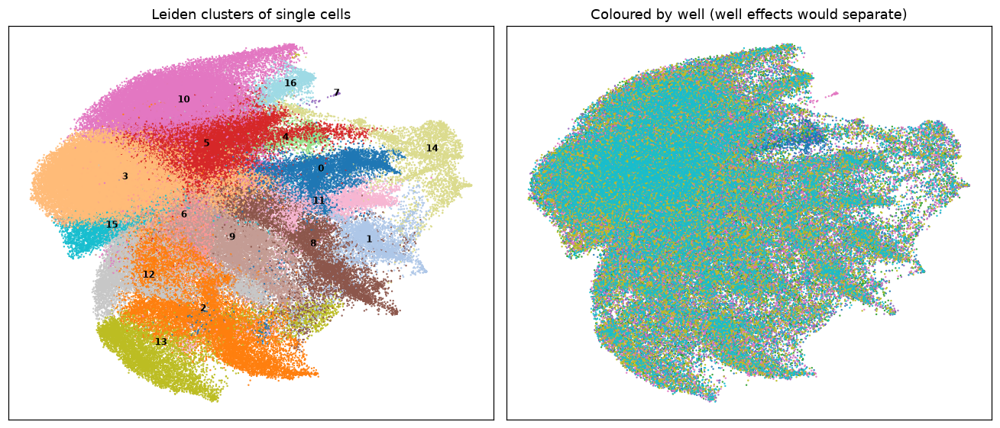

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
lab = norm_sub.obs["leiden"].astype(int).to_numpy()
axes[0].scatter(u[:, 0], u[:, 1], c=lab, cmap="tab20", s=0.3, rasterized=True)
for c in np.unique(lab):
    axes[0].text(*np.median(u[lab == c], axis=0), str(c), fontsize=8, weight="bold")
axes[0].set(title="Leiden clusters of single cells", xticks=[], yticks=[])
wl = pd.factorize(norm_sub.obs["Metadata_Well"])[0]
axes[1].scatter(u[:, 0], u[:, 1], c=wl, cmap="tab10", s=0.3, rasterized=True)
axes[1].set(title="Coloured by well (well effects would separate)", xticks=[], yticks=[])
fig.tight_layout()
save("cells_umap_clusters_wells", fig)

{'G1': 0.597, 'G2M': 0.247, 'S': 0.156}


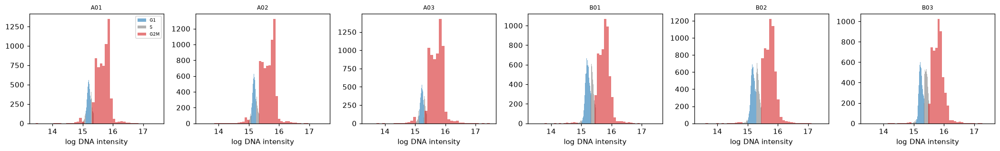

In [24]:
mt.tl.cell_cycle_phase(raw_sub, dna_feature=DNA, by="Metadata_Well")
print(raw_sub.obs["Metadata_CellCyclePhase"].value_counts(normalize=True).round(3).to_dict())
mt.pl.cell_cycle(raw_sub, dna_feature=DNA, by="Metadata_Well")
save("cells_cell_cycle_dna")

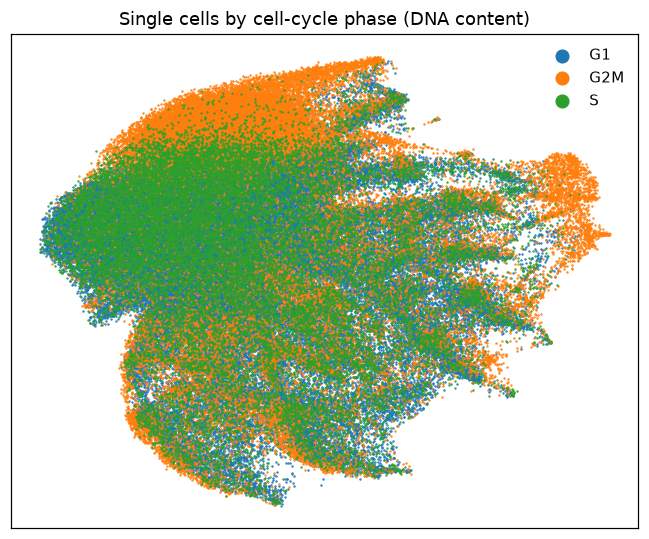

In [25]:
fig, ax = plt.subplots(figsize=(6, 5))
ph = pd.factorize(raw_sub.obs["Metadata_CellCyclePhase"].astype(str))
for k, name in enumerate(ph[1]):
    m = ph[0] == k
    ax.scatter(u[m, 0], u[m, 1], s=0.3, label=name, rasterized=True)
ax.legend(markerscale=15, frameon=False)
ax.set(title="Single cells by cell-cycle phase (DNA content)", xticks=[], yticks=[])
fig.tight_layout()
save("cells_umap_phase", fig)

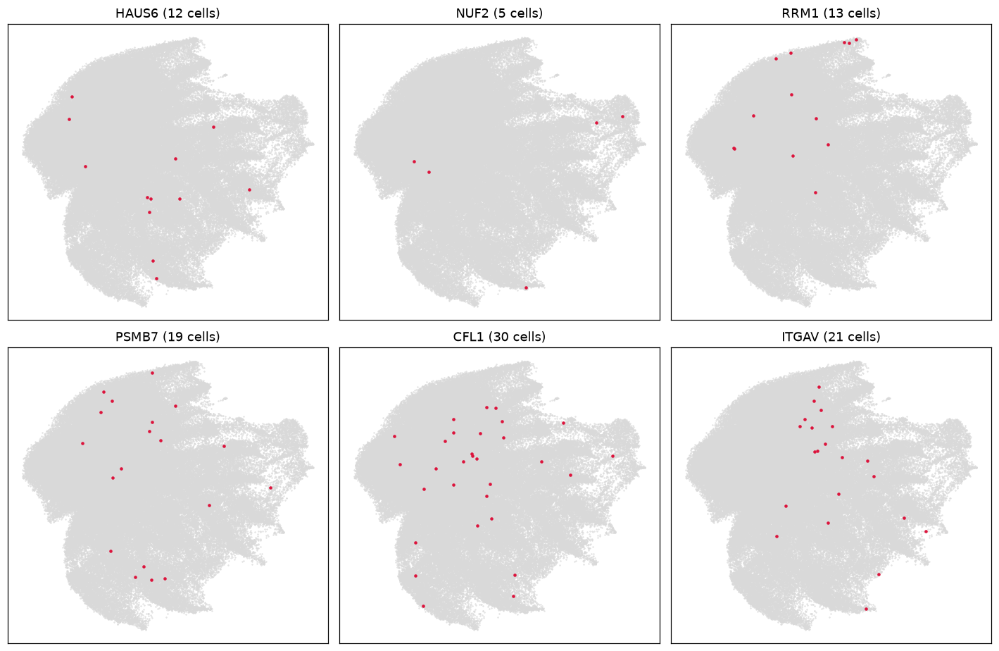

In [26]:
# Density of a few knockouts' cells on the single-cell map, against all cells in grey.
SHOW = ["HAUS6", "NUF2", "RRM1", "PSMB7", "CFL1", "ITGAV"]
gsub = norm_sub.obs["Metadata_Gene"].astype(str).to_numpy()
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for ax, g in zip(axes.ravel(), SHOW):
    m = gsub == g
    ax.scatter(u[:, 0], u[:, 1], s=0.2, c="0.85", rasterized=True)
    ax.scatter(u[m, 0], u[m, 1], s=4, c=HIT)
    ax.set(title=f"{g} ({m.sum()} cells)", xticks=[], yticks=[])
fig.tight_layout()
save("cells_umap_knockouts", fig)

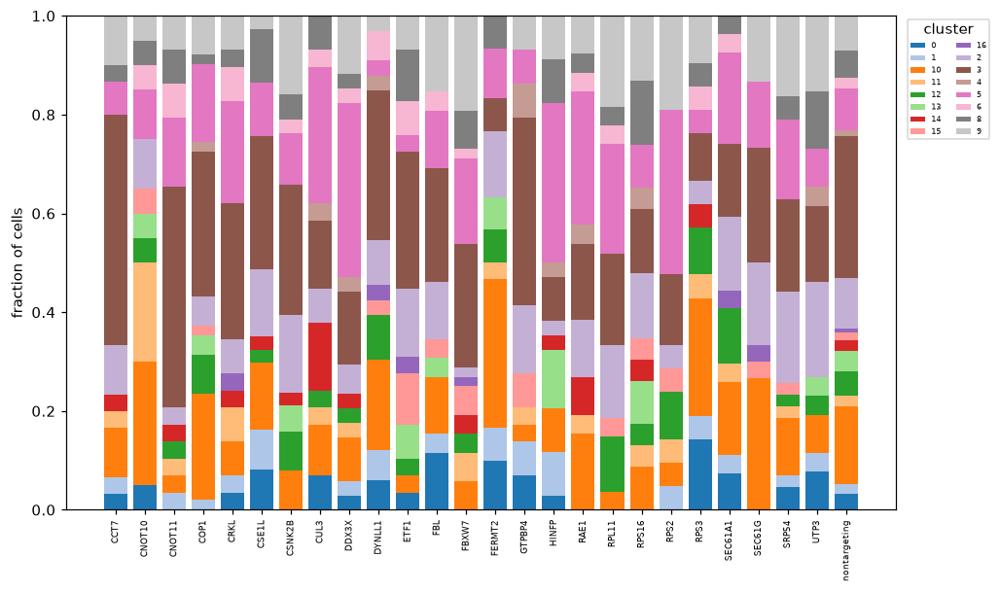

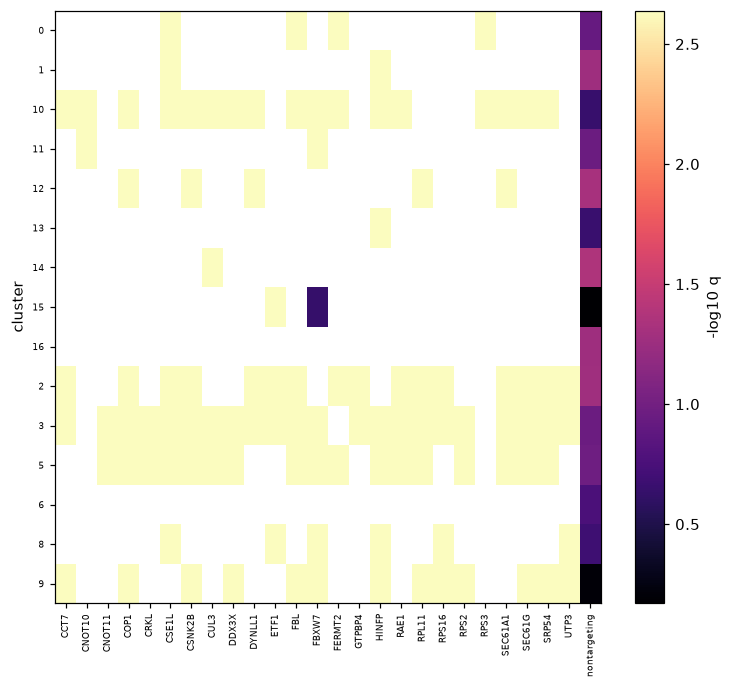

In [27]:
gene_counts = norm_sub.obs["Metadata_Gene"].astype(str).value_counts()
top_genes = [g for g in p_calls[p_calls["beyond_cutting"]].sort_values("score", ascending=False).index if gene_counts.get(g, 0) >= 20][:25]
small = norm_sub[(norm_sub.obs["Metadata_Gene"].astype(str).isin(top_genes) | (norm_sub.obs["Metadata_Control_Type"] == "negcon")).to_numpy()].copy()
small.obs["Metadata_Perturbation"] = small.obs["Metadata_Gene"].astype(str)
composition = mt.tl.cluster_composition(small, cluster_key="leiden", by=("Metadata_Perturbation",))
fig, ax = plt.subplots(figsize=(10, 6))
mt.pl.cluster_composition(composition, ax=ax)
save("cells_cluster_composition", fig)
mt.tl.subpopulation_hits(small, cluster_key="leiden", groupby="Metadata_Perturbation", use_rep="X_pca", n_permutations=500)
fig, ax = plt.subplots(figsize=(8, 7))
mt.pl.subpopulation_hits(small, ax=ax)
save("cells_subpopulation_hits", fig)

## Guide and gene embeddings

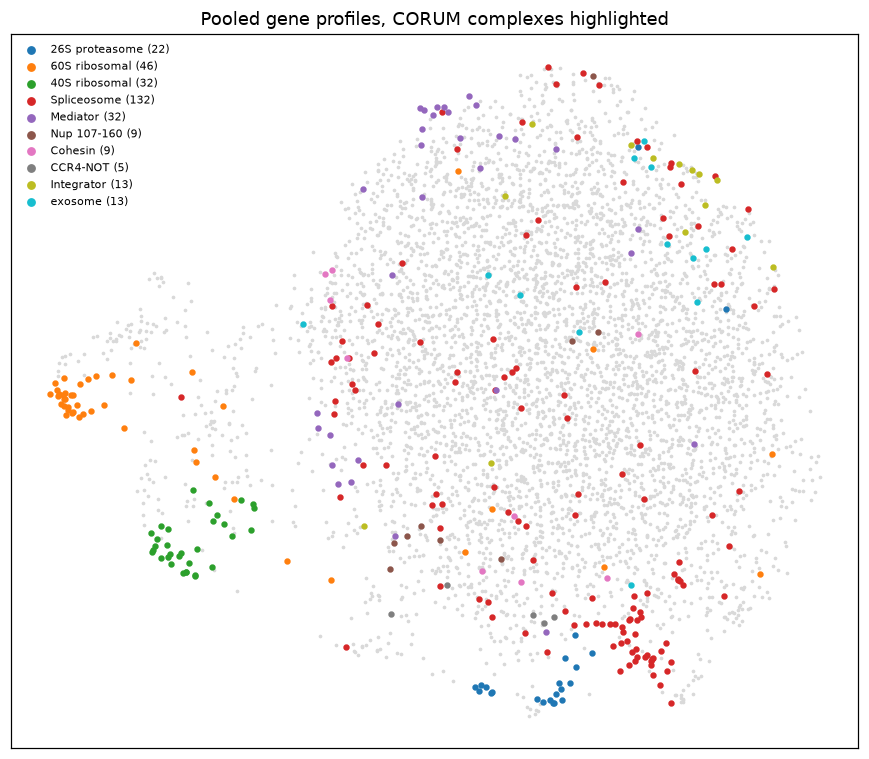

In [28]:
corum = mt.ds.corum()
COMPLEXES = {}
for key in ["26S proteasome", "60S ribosomal", "40S ribosomal", "Spliceosome", "Mediator", "Nup 107-160", "Cohesin", "CCR4-NOT", "Integrator", "exosome"]:
    hit = [s for s in corum["source"].unique() if key.lower() in s.lower()]
    if hit:
        best = max(hit, key=lambda s: (corum["source"] == s).sum())
        COMPLEXES[key] = set(corum.loc[corum["source"] == best, "target"].astype(str))

pooled = genes[~genes.obs["Gene_Unit"].astype(str).str.startswith("NTC")].copy()
pooled.obs_names = pooled.obs["Gene_Unit"].astype(str).to_numpy()
sc.pp.pca(pooled, n_comps=50, random_state=SEED)
sc.pp.neighbors(pooled, n_neighbors=15, random_state=SEED)
sc.tl.umap(pooled, random_state=SEED)
sc.tl.leiden(pooled, resolution=2.0, key_added="cluster", flavor="igraph", n_iterations=2, random_state=SEED)
pu = pooled.obsm["X_umap"]
names = pooled.obs_names.to_numpy()


def complex_panel(ax, coords, names, title):
    ax.scatter(coords[:, 0], coords[:, 1], s=2, c="0.85", rasterized=True)
    cmap = plt.get_cmap("tab10")
    for k, (cx, members) in enumerate(COMPLEXES.items()):
        m = np.isin(names, list(members))
        ax.scatter(coords[m, 0], coords[m, 1], s=10, color=cmap(k % 10), label=f"{cx} ({m.sum()})")
    ax.legend(frameon=False, fontsize=7, markerscale=1.5, loc="best")
    ax.set(title=title, xticks=[], yticks=[])


fig, ax = plt.subplots(figsize=(8, 7))
complex_panel(ax, pu, names, "Pooled gene profiles, CORUM complexes highlighted")
fig.tight_layout()
save("genes_umap_complexes", fig)

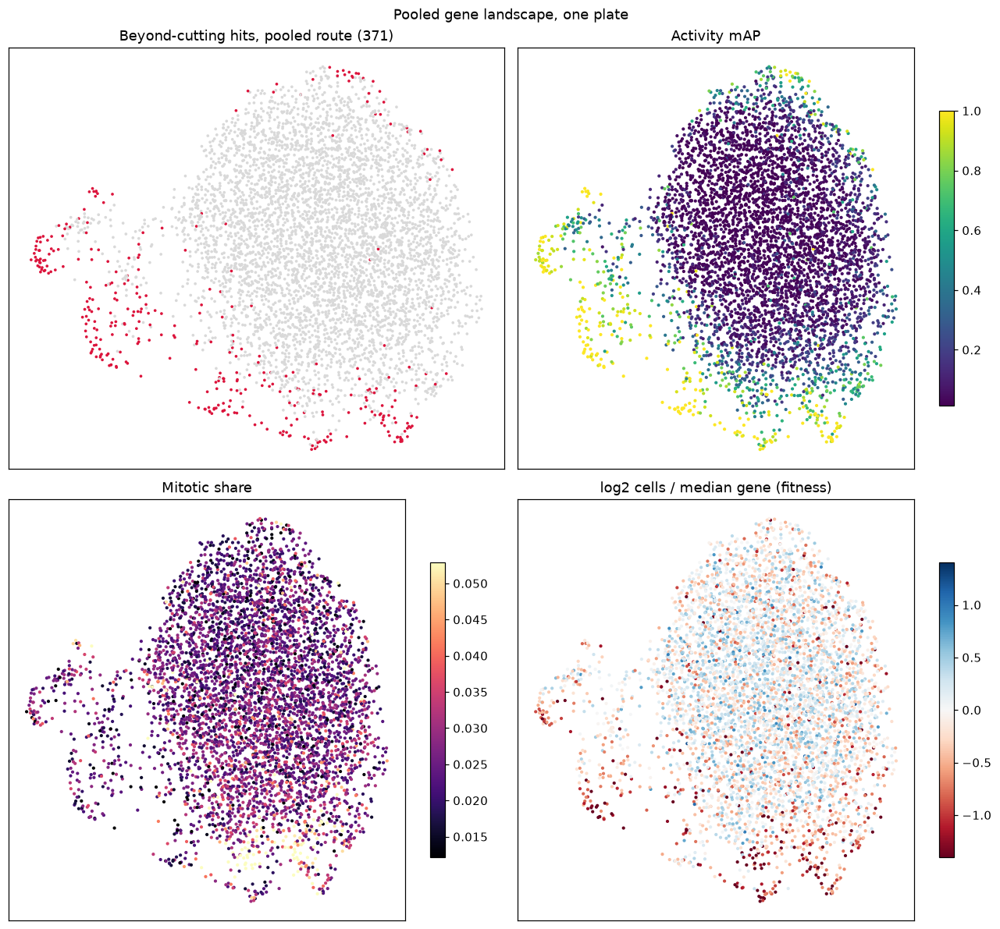

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
bc = p_calls["beyond_cutting"].reindex(names).fillna(False).to_numpy()
axes[0, 0].scatter(pu[:, 0], pu[:, 1], s=2, c=np.where(bc, HIT, "0.85"), rasterized=True)
axes[0, 0].set(title=f"Beyond-cutting hits, pooled route ({bc.sum()})")
for ax, (title, val, cmap) in zip(
    axes.ravel()[1:],
    [("Activity mAP", p_calls["score"].reindex(names).to_numpy(), "viridis"),
     ("Mitotic share", mito_gene.reindex(names).to_numpy(), "magma"),
     ("log2 cells / median gene (fitness)", viab.reindex(names).to_numpy(), "RdBu")],
):
    lo, hi = np.nanpercentile(val, [2, 98])
    if cmap == "RdBu":
        lo, hi = -max(abs(lo), abs(hi)), max(abs(lo), abs(hi))
    s = ax.scatter(pu[:, 0], pu[:, 1], s=3, c=val, cmap=cmap, vmin=lo, vmax=hi, rasterized=True)
    fig.colorbar(s, ax=ax, shrink=0.7)
    ax.set(title=title)
for ax in axes.ravel():
    ax.set(xticks=[], yticks=[])
fig.suptitle("Pooled gene landscape, one plate")
fig.tight_layout()
save("genes_umap_annotations", fig)

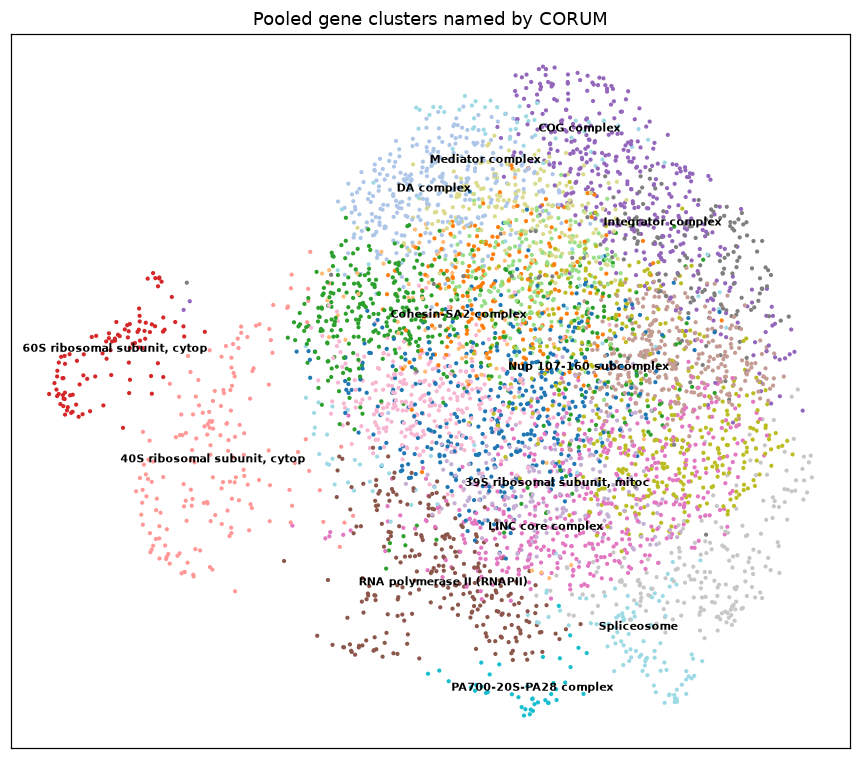

In [30]:
fig, ax = plt.subplots(figsize=(8, 7))
lab = pooled.obs["cluster"].astype(int).to_numpy()
ax.scatter(pu[:, 0], pu[:, 1], c=lab, cmap="tab20", s=3, rasterized=True)
mt.tl.ora(pooled, groupby="cluster", net=corum, gene_key="Metadata_Gene", tmin=4, padj_by="group")
ora = pd.DataFrame(pooled.uns["mantispy"]["ora"])
best = ora[ora["odds_ratio"] > 0].sort_values("qvalue").groupby("group").head(1)
best = best[best["qvalue"] < 1e-3].set_index("group")["source"]
for c in np.unique(lab):
    name = best.get(str(c))
    if name is not None:
        ax.text(*np.median(pu[lab == c], axis=0), name[:28], fontsize=7, weight="bold", ha="center")
ax.set(title="Pooled gene clusters named by CORUM", xticks=[], yticks=[])
fig.tight_layout()
save("genes_umap_named_clusters", fig)

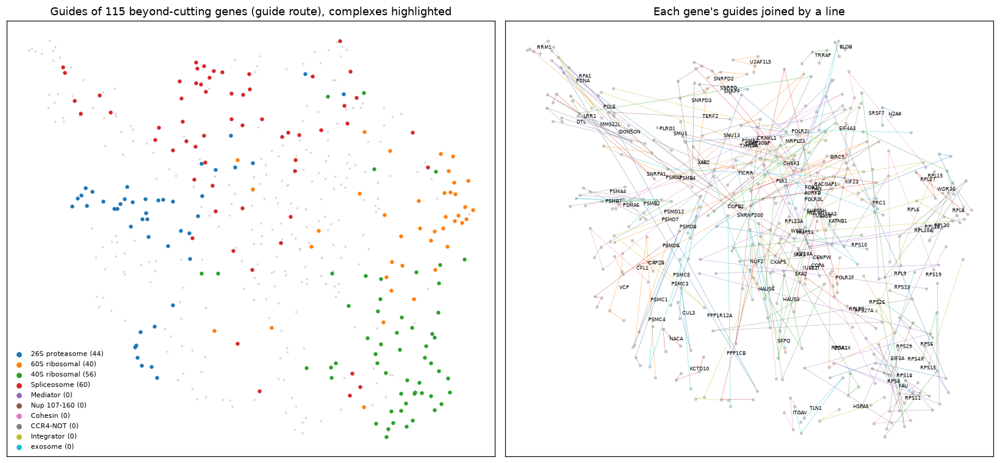

In [31]:
# Guides of strong genes: do a gene's guides sit together?
strong = g_calls[g_calls["beyond_cutting"]].index
gsel = guides[guides.obs["Analysis_Group"].astype(str).isin(strong).to_numpy()].copy()
sc.pp.neighbors(gsel, n_neighbors=10, use_rep="X_pca", random_state=SEED)
sc.tl.umap(gsel, random_state=SEED)
gu = gsel.obsm["X_umap"]
gg = gsel.obs["Analysis_Group"].astype(str).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
complex_panel(axes[0], gu, gg, f"Guides of {len(strong)} beyond-cutting genes (guide route), complexes highlighted")
axes[1].scatter(gu[:, 0], gu[:, 1], s=6, c="0.8")
for g in strong:
    m = gg == g
    if m.sum() >= 2:
        axes[1].plot(gu[m, 0], gu[m, 1], lw=0.4, alpha=0.6)
    axes[1].text(*gu[m].mean(0), g, fontsize=5)
axes[1].set(title="Each gene's guides joined by a line", xticks=[], yticks=[])
fig.tight_layout()
save("guides_umap_strong_genes", fig)

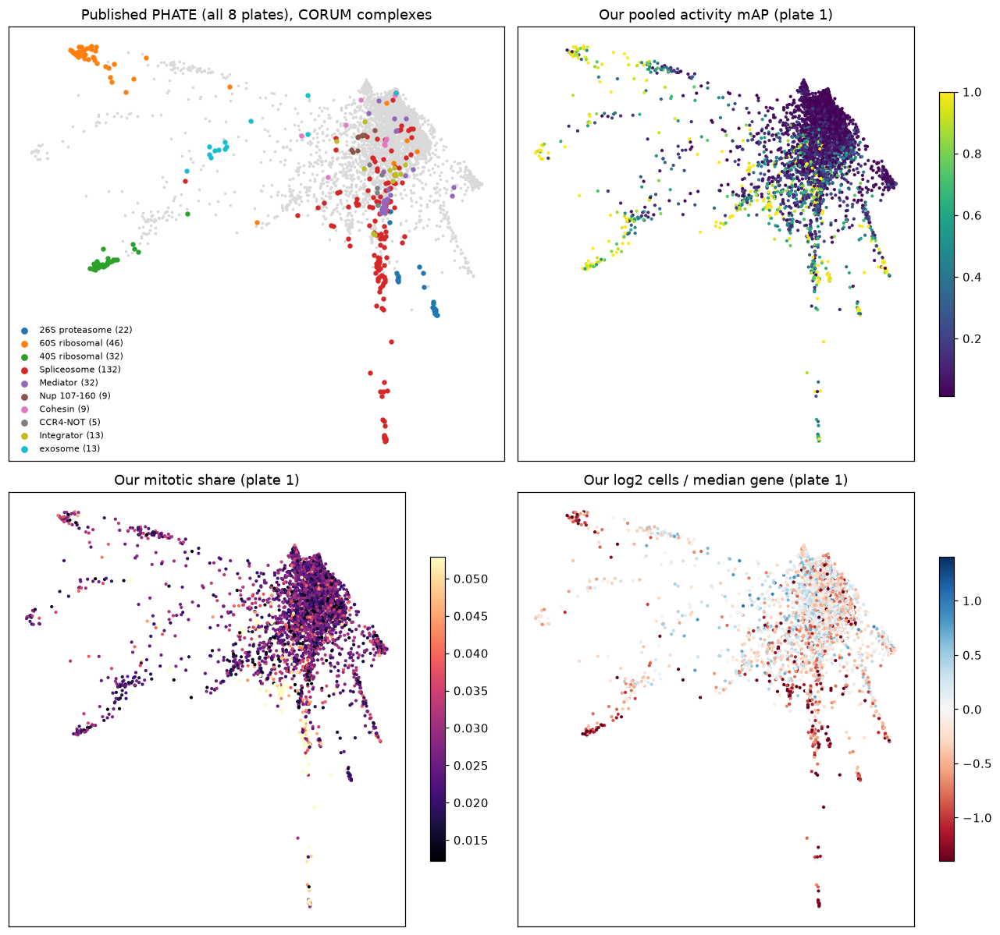

In [32]:
published = ad.read_h5ad(
    pooch.retrieve(
        "https://ops-explorer-public.s3.amazonaws.com/aconcagua/aconcagua/visualizations/interphase/aggregated_data.h5ad",
        known_hash="sha256:f55756939edc8ddf108092d88c4efe248765b4db4ec39322d4b4a988e04af929",
        fname="brief_interphase.h5ad",
    )
)
ph = np.asarray(published.obsm["X_phate"])
pn = published.obs_names.astype(str).to_numpy()
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
complex_panel(axes[0, 0], ph, pn, "Published PHATE (all 8 plates), CORUM complexes")
for ax, (title, val, cmap) in zip(
    axes.ravel()[1:],
    [("Our pooled activity mAP (plate 1)", p_calls["score"].reindex(pn).to_numpy(), "viridis"),
     ("Our mitotic share (plate 1)", mito_gene.reindex(pn).to_numpy(), "magma"),
     ("Our log2 cells / median gene (plate 1)", viab.reindex(pn).to_numpy(), "RdBu")],
):
    lo, hi = np.nanpercentile(val, [2, 98])
    if cmap == "RdBu":
        lo, hi = -max(abs(lo), abs(hi)), max(abs(lo), abs(hi))
    s = ax.scatter(ph[:, 0], ph[:, 1], s=3, c=val, cmap=cmap, vmin=lo, vmax=hi, rasterized=True)
    fig.colorbar(s, ax=ax, shrink=0.7)
    ax.set(title=title, xticks=[], yticks=[])
fig.tight_layout()
save("published_phate_overlays", fig)

## Landscape: similarity among the strongest genes

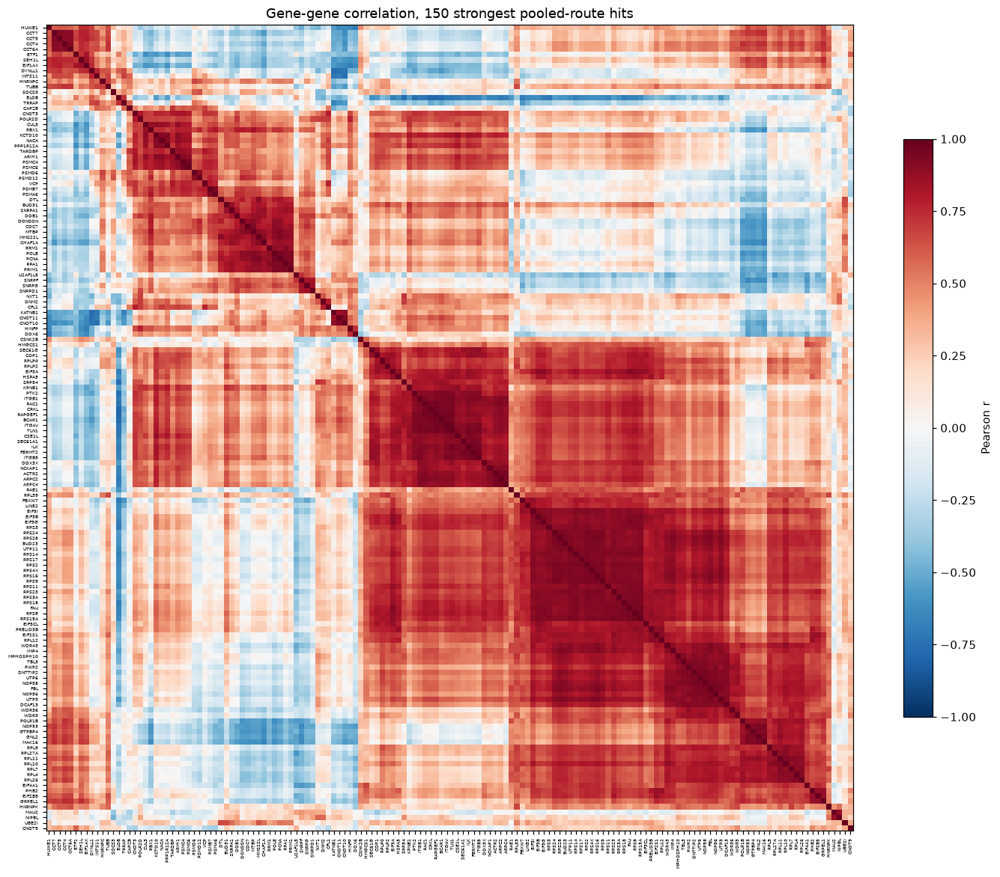

In [33]:
top = p_calls[p_calls["beyond_cutting"]].sort_values("score", ascending=False).index[:150]
top = [g for g in top if g in pooled.obs_names]
X = np.asarray(pooled[top].X)
C = np.corrcoef(X)
order = leaves_list(linkage(squareform(1 - C, checks=False), method="average"))
fig, ax = plt.subplots(figsize=(13, 12))
im = ax.imshow(C[np.ix_(order, order)], cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(top)), np.array(top)[order], rotation=90, fontsize=4)
ax.set_yticks(range(len(top)), np.array(top)[order], fontsize=4)
fig.colorbar(im, ax=ax, shrink=0.6, label="Pearson r")
ax.set_title(f"Gene-gene correlation, {len(top)} strongest pooled-route hits")
fig.tight_layout()
save("landscape_hit_correlation_heatmap", fig)

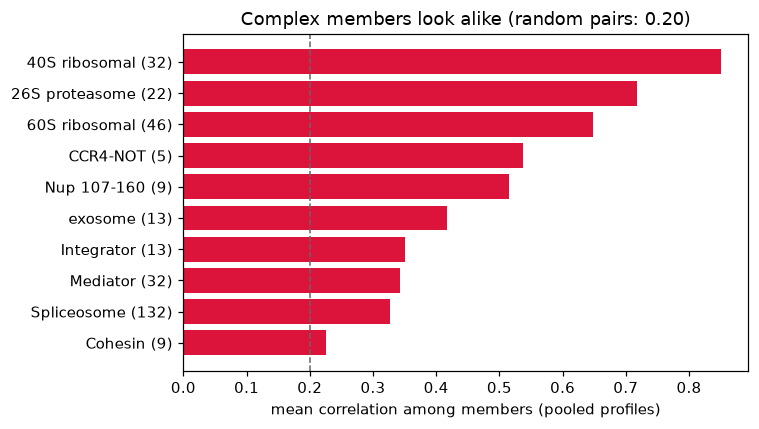

In [34]:
rows = []
for cx, members in COMPLEXES.items():
    m = [g for g in members if g in pooled.obs_names]
    if len(m) >= 3:
        c = np.corrcoef(np.asarray(pooled[m].X))
        rows.append((cx, len(m), c[np.triu_indices(len(m), 1)].mean()))
rnd = np.corrcoef(np.asarray(pooled[np.random.default_rng(SEED).choice(pooled.n_obs, 300, replace=False)].X))
base = rnd[np.triu_indices(300, 1)].mean()
t = pd.DataFrame(rows, columns=["complex", "members", "mean r"]).sort_values("mean r")
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(t["complex"] + " (" + t["members"].astype(str) + ")", t["mean r"], color=HIT)
ax.axvline(base, color="0.4", ls="--", lw=1)
ax.set(xlabel="mean correlation among members (pooled profiles)", title=f"Complex members look alike (random pairs: {base:.2f})")
fig.tight_layout()
save("landscape_complex_coherence_bars", fig)

In [35]:
lap("done")
print(sorted(p.name for p in FIGS.glob("*.png")))

[  1004s] done
['cells_cell_cycle_dna.png', 'cells_cluster_composition.png', 'cells_subpopulation_hits.png', 'cells_umap_clusters_wells.png', 'cells_umap_features.png', 'cells_umap_knockouts.png', 'cells_umap_phase.png', 'genes_umap_annotations.png', 'genes_umap_complexes.png', 'genes_umap_named_clusters.png', 'guides_umap_strong_genes.png', 'hits_empirical_null.png', 'hits_feature_volcanoes.png', 'hits_mahalanobis.png', 'hits_map_activity.png', 'hits_map_volcano.png', 'hits_ranked.png', 'landscape_complex_coherence_bars.png', 'landscape_hit_correlation_heatmap.png', 'published_phate_overlays.png', 'qc_barcode_and_classifier.png', 'qc_cells_per_well.png', 'qc_feature_groups_selected.png', 'qc_replicate_correlation.png', 'qc_representation.png', 'qc_well_density.png', 'qc_well_drift_and_variance.png', 'qc_well_mitotic_map.png', 'viability_cytotoxicity.png', 'viability_guides_hexbin.png', 'viability_vs_mitotic.png', 'viability_vs_strength.png']
